# Electronics Classifier: full-pipeline demo notebook

This notebook runs the **whole** `electronics_classifier` pipeline on **every test image** and shows:

1. all **annotated images** in one matplotlib grid,
2. every image's **JSON output**, exactly as the pipeline produces it,
3. a short **summary table** (items found, categories, warnings, time per image).

It lives *outside* the `electronics_classifier/` package on purpose. It only *imports* the package, so nothing in the package has to change.

### How the notebook is organised

| Section | What it does | What you can swap |
|---|---|---|
| 1. Setup | imports, finds the project folder | the project location |
| 2. Configuration | **every knob in one cell** | images, presets, overrides, VLM, detector, display |
| 3. Building blocks | small, separate functions | each function can be replaced |
| 4. Swap points | names that point at the functions | re-point a name to your own function |
| 5. Run | runs the pipeline on all images | nothing (it only calls the swap points) |
| 6-8. Display | image grid, JSON, summary | the display functions |
| 9. Optional | save to disk, inspect filter steps | toggles in the configuration |

**Pipeline stages (for reference):** image preprocess -> detector (**RAM++ tags the photo, GroundingDINO boxes the tags**) -> detection filters -> segmenter (**SAM masks**) -> crops -> VLM (**validates the detection, then reads brand / model / color**) -> attribute post-processing -> warning rules -> assemble -> render.

This is the default **Grounded-SAM + RAM++** pipeline. Items the VLM says are not electronic devices are dropped (the summary shows how many). The previous pipeline (GroundingDINO prompted with a fixed vocabulary, no masks) is still available as the `baseline` preset: set `PRESETS = ["baseline"]` in the configuration cell.

**Memory:** on a 16 GB Apple Silicon Mac the detection models and an 8B VLM do not fit together comfortably. With `TWO_PHASE = True` (the default) the notebook detects and masks every image first, frees those models, and only then calls the VLM. Set it to `False` to process one image completely before the next.

## 1. Setup

Standard imports first, then a helper that **finds the project folder** no matter where Jupyter was started.

In [1]:
# --- Standard library -----------------------------------------------------------------
import json                      # to pretty-print / save the JSON results
import os                        # to change the working directory
import sys                       # to make the package importable
import time                      # to time each image
from dataclasses import dataclass, field   # a tidy container for one image's results
from pathlib import Path         # path handling that works on macOS / Linux / Windows
from typing import Any, Callable

# --- Third party ----------------------------------------------------------------------
import matplotlib.pyplot as plt  # the annotated-image grid
import numpy as np               # images are (H, W, 3) uint8 arrays
from PIL import Image            # used only to shrink images before plotting

# Quieter, more readable output: hide the very chatty library warnings.
import warnings
warnings.filterwarnings("ignore")

In [2]:
def find_project_dir(name: str = "electronics_classifier") -> Path:
    """Walk up from the current folder until a folder called ``name`` is found.

    Jupyter starts with the notebook's own folder as the working directory, so for this
    notebook the project folder is normally right next to it. Searching upward as well
    means the notebook still works if you move it into a sub-folder.
    """
    here = Path.cwd().resolve()
    for folder in (here, *here.parents):
        candidate = folder / name
        if (candidate / "src" / name).is_dir():      # looks like the real package folder
            return candidate
    raise FileNotFoundError(
        f"Could not find a '{name}' folder above {here}. "
        "Set PROJECT_DIR by hand in the configuration cell."
    )

## 2. Configuration: change things here first

**Everything you are likely to change is in this one cell.** The later cells only *read* these names.

Three layers of pipeline configuration are combined, in this order (later wins):

1. the built-in `config/pipeline.yaml` (or `BASE_CONFIG_PATH` if you set it),
2. **presets** (`PRESETS`): named YAML files in `config/presets/` such as `open_vocab`, `fast`, `accurate_sam`,
3. **override files** (`OVERRIDE_FILES`) and finally **`SETS`**, single `dotted.key=value` edits.

`SETS` is the quickest way to swap a component for a one-off experiment. Examples are included as comments.

In [3]:
# =====================================================================================
# WHERE THE PROJECT AND IMAGES ARE
# =====================================================================================
PROJECT_DIR = find_project_dir()                 # or: Path("/full/path/to/electronics_classifier")
IMAGE_DIR = PROJECT_DIR / "test_images"          # folder with the photos to classify
IMAGE_PATTERNS = ["*.heic", "*.HEIC", "*.jpg", "*.jpeg", "*.png"]   # which files count as images
ONLY = []             # keep only files whose name contains one of these, e.g. ["5255", "5245"]
MAX_IMAGES = None     # e.g. 3 to try just the first three images; None = all of them

# =====================================================================================
# HOW THE PIPELINE IS CONFIGURED
# =====================================================================================
BASE_CONFIG_PATH = None            # None = built-in config/pipeline.yaml
PRESETS = []                       # [] = default Grounded-SAM + RAM++. e.g. ["baseline"] (old DINO pipeline), ["fast"] (2B VLM)
# Do NOT add "open_vocab" here: it swaps in a prompt without the is_electronic verdict, which
# would switch the VLM validation off. The default pipeline already allows open categories.
OVERRIDE_FILES = []                # paths to extra YAML override files
SETS = [
    # ---- uncomment / edit any line to swap a feature -------------------------------
    # "pipeline.detector.params.ram_on_cpu=true",             # run RAM++ on the CPU if the GPU (mps) fails
    # "pipeline.detector.params.include_vocabulary=false",    # prompt DINO with the RAM++ tags only
    # "pipeline.segmenter.name=none",                         # no SAM masks (plain rectangular crops)
    # "pipeline.vlm.on_not_electronic=warn",                  # keep non-device items, flagged NOT_ELECTRONIC
    # "pipeline.vlm.client.name=transformers",                 # run the VLM in-process instead of Ollama
    # "pipeline.vlm.client.params.model=qwen3-vl:8b-instruct",  # another model name on the same server
    # "pipeline.detector.params.model_id=IDEA-Research/grounding-dino-base",   # bigger detector
    # "pipeline.detection_filters=[{name: top_k, params: {k: 3}}]",            # replace the whole filter list
    # "pipeline.crop.padding_ratio=0.25",                      # more context around each crop
    # "rendering.output_format=jpeg",
    # "run.seed=1",
]
EXTRA_COMPONENTS = {}
# Advanced: inject ready-made component objects instead of config. Allowed keys:
#   image_preprocess, detector, detection_filters, segmenter, segmentation_gate,
#   crop_transforms, vlm_client, attribute_postprocess, warning_rules
# Example: EXTRA_COMPONENTS = {"vlm_client": MyOwnVlmClient()}

# =====================================================================================
# HOW THE RUN BEHAVES
# =====================================================================================
USE_FAKE_VLM = False     # True = skip the real VLM (fast; every item answers "router"). Good for testing the plumbing.
CAPTURE_TRACE = True     # True = keep every stage's intermediate result (section 9) and show how many items the VLM dropped
TWO_PHASE = True         # True = detect + mask EVERY image first, free those models, THEN run the VLM (needs far less memory at once)
FREE_GPU_MEMORY = True   # True = hand cached GPU memory back to the system after every image (matters on Apple Silicon, where the GPU shares RAM)
STOP_ON_ERROR = False    # False = a failing image is reported and the rest still run
LOG_LEVEL = "WARNING"    # "WARNING" also shows degraded steps (RAM++ tagging failed, SAM failed); "ERROR" is quieter; "DEBUG" shows more

# =====================================================================================
# HOW RESULTS ARE SHOWN / SAVED
# =====================================================================================
GRID_COLS = 3                 # images per row in the annotated-image grid
CELL_SIZE = (6, 7.5)          # width, height in inches of one grid cell
DISPLAY_MAX_SIDE = 1400       # shrink images to this size before plotting (keeps the notebook light)
JSON_DROP_META = False        # True = hide the "meta" block (config hash + component names) from the printout
SAVE_DIR = None               # e.g. Path("notebook_outputs") to also write annotated.png + result.json per image

In [4]:
# --- Make the package importable and put the working directory where the config expects it --
# 1) The package lives in <project>/src. Adding it to sys.path means this works even if the
#    package was never `pip install`-ed into this kernel's environment.
sys.path.insert(0, str(PROJECT_DIR / "src"))

# 2) Some config values are *relative paths* (for example the RAM++ checkpoint,
#    checkpoints/ram_plus_swin_large_14m.pth, and the VLM prompt in config/prompts/). They are resolved from the working directory,
#    so we run from the project folder. We make IMAGE_DIR absolute first so it keeps working.
IMAGE_DIR = Path(IMAGE_DIR).resolve()
os.chdir(PROJECT_DIR)

# 3) The package reports many small events through Python's logging (for example every
#    detection it drops). LOG_LEVEL decides how many of those messages reach the notebook.
import logging
logging.getLogger("electronics_classifier").setLevel(LOG_LEVEL)

# Hide the harmless progress bars that Hugging Face prints while loading models.
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")

print("project :", PROJECT_DIR)
print("images  :", IMAGE_DIR)
print("cwd     :", Path.cwd())

project : /Users/sowmyan/Developer/E-NaviWaste/electronics_classifier
images  : /Users/sowmyan/Developer/E-NaviWaste/electronics_classifier/test_images
cwd     : /Users/sowmyan/Developer/E-NaviWaste/electronics_classifier


## 3. Building blocks

Each function below does **one** job and has a docstring that says what goes in and what comes out. Section 4 gives each one a *swap-point name*, so you can replace any of them with your own version without touching the rest.

### 3a. Finding and loading images

In [5]:
def discover_images(folder: Path, patterns: list[str], only: list[str], limit: int | None) -> list[Path]:
    """Return the image files in ``folder`` matching ``patterns``, sorted by name.

    ``only``  : keep a file only if its name contains one of these strings (empty list = keep all).
    ``limit`` : keep at most this many files (``None`` = no limit).
    """
    found: dict[str, Path] = {}
    for pattern in patterns:
        for path in folder.glob(pattern):
            found[path.name.lower()] = path          # lower-cased key stops *.heic / *.HEIC duplicates
    paths = sorted(found.values(), key=lambda p: p.name.lower())
    if only:
        paths = [p for p in paths if any(token in p.name for token in only)]
    return paths[:limit] if limit else paths

In [6]:
def load_image_default(path: Path) -> np.ndarray:
    """Read one photo as an upright ``(H, W, 3)`` uint8 RGB array.

    This reuses the package's own loader, so it is exactly what the command line does: it
    honours the EXIF rotation and understands iPhone HEIC files (via ``pillow-heif``).
    """
    from electronics_classifier.cli import load_image
    return load_image(path)

### 3b. Building the pipeline

The pipeline loads its models once, so we **build it one time** and reuse it for every image. All configuration errors (a wrong model name, a missing file, a server that is down) are raised here, before any image is processed.

In [7]:
def build_pipeline_default(
    presets: list[str],
    override_files: list,
    sets: list[str],
    base_config_path=None,
    components: dict | None = None,
):
    """Create an ``ElectronicsClassificationPipeline`` from the configuration layers."""
    from electronics_classifier import ElectronicsClassificationPipeline
    return ElectronicsClassificationPipeline(
        config_path=base_config_path,
        presets=presets,
        overrides=override_files,
        sets=sets,
        **(components or {}),          # optional injected components (see EXTRA_COMPONENTS)
    )

### 3c. Classifying one image

`ImageRun` is a small record that holds everything about one image: the original, the annotated output, the result object, the timing, and an error message if it failed. The display functions only need this record, which keeps the run and the display independent.

In [8]:
@dataclass
class ImageRun:
    """Everything we keep about one processed image."""
    name: str                          # file name, e.g. "IMG_5255.HEIC"
    path: Path
    original: np.ndarray | None = None     # the loaded photo (RGB)
    annotated: np.ndarray | None = None    # the pipeline's annotated picture (RGB)
    result: Any = None                     # a ClassificationResult (pydantic model)
    trace: Any = None                      # a PipelineTrace, only if CAPTURE_TRACE
    seconds: float = 0.0
    error: str | None = None               # filled in when the image failed

    @property
    def ok(self) -> bool:
        return self.error is None and self.result is not None

In [9]:
def classify_default(pipeline, image: np.ndarray, capture_trace: bool = False):
    """Run the pipeline on one image. Returns ``(annotated, result, trace_or_None)``.

    ``pipeline.run`` returns ``(annotated, result)``, or ``(annotated, result, trace)`` when
    ``return_trace=True``. This wrapper hides that difference.
    """
    outputs = pipeline.run(image, return_trace=capture_trace)
    annotated, result = outputs[0], outputs[1]
    trace = outputs[2] if capture_trace else None
    return annotated, result, trace

In [10]:
def run_all(
    paths: list[Path],
    pipeline,
    image_loader: Callable,
    classifier: Callable,
    capture_trace: bool = False,
    stop_on_error: bool = False,
    cleanup: Callable | None = None,
) -> list[ImageRun]:
    """Process every image with the given pipeline and return one ``ImageRun`` each.

    The loader and the classifier are passed in as arguments (not hard-coded), so you can
    swap either one without editing this loop.
    """
    runs: list[ImageRun] = []
    for number, path in enumerate(paths, 1):
        run = ImageRun(name=path.name, path=path)
        started = time.perf_counter()
        try:
            run.original = image_loader(path)
            run.annotated, run.result, run.trace = classifier(pipeline, run.original, capture_trace)
        except Exception as exc:                       # report and carry on with the next image
            if stop_on_error:
                raise
            run.error = f"{type(exc).__name__}: {exc}"
        run.seconds = time.perf_counter() - started
        status = "ok" if run.ok else f"FAILED ({run.error})"
        items = len(run.result.items) if run.ok else 0
        print(f"[{number:>2}/{len(paths)}] {run.name:<18} {run.seconds:6.1f}s  {items} item(s)  {status}")
        runs.append(run)
        if cleanup is not None:
            cleanup()                                  # e.g. free_gpu_memory
    return runs

In [11]:
def free_gpu_memory() -> None:
    """Hand cached GPU memory back to the system.

    On Apple Silicon the GPU shares RAM with everything else, and PyTorch keeps freed GPU memory
    cached for reuse. Calling this between images stops that cache from growing into swap.
    """
    import gc
    gc.collect()
    try:
        import torch
    except ImportError:
        return
    if torch.backends.mps.is_available():
        torch.mps.empty_cache()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def run_all_two_phase(
    paths: list[Path],
    pipeline,
    image_loader: Callable,
    classifier: Callable,
    capture_trace: bool = False,
    stop_on_error: bool = False,
    cleanup: Callable | None = None,
) -> list[ImageRun]:
    """Two passes, so the detection models and the VLM never need memory at the same time.

    Phase 1 runs ``pipeline.detect`` (RAM++, GroundingDINO, SAM, crops) on EVERY image.
    Then the detection models are released and their memory is freed.
    Phase 2 runs ``pipeline.classify`` (the VLM, post-processing, warnings, drawing) on every image.

    The result is identical to ``run_all``. ``classifier`` is not used here because this function
    calls ``detect`` and ``classify`` itself. The pipeline cannot detect again afterwards:
    re-run the "build the pipeline" cell before running the images a second time.
    """
    from electronics_classifier.trace import PipelineTrace

    runs = [ImageRun(name=path.name, path=path) for path in paths]
    detected: dict[int, Any] = {}

    print("PHASE 1/2: detection + masks (the VLM is not used yet)")
    for number, run in enumerate(runs, 1):
        started = time.perf_counter()
        try:
            run.original = image_loader(run.path)
            run.trace = PipelineTrace() if capture_trace else None
            detected[number - 1] = pipeline.detect(run.original, run.trace)
        except Exception as exc:
            if stop_on_error:
                raise
            run.error = f"{type(exc).__name__}: {exc}"
        run.seconds += time.perf_counter() - started
        found = len(detected[number - 1].items) if number - 1 in detected else 0
        status = "ok" if run.error is None else f"FAILED ({run.error})"
        print(f"  [{number:>2}/{len(runs)}] {run.name:<18} {run.seconds:6.1f}s  {found} candidate(s)  {status}")
        if cleanup is not None:
            cleanup()

    pipeline.release_detection_models()                # drop RAM++, GroundingDINO and SAM
    if cleanup is not None:
        cleanup()
    print("detection models released; GPU memory freed")

    print("PHASE 2/2: VLM validation + attributes")
    for number, run in enumerate(runs, 1):
        if run.error is not None:
            continue
        started = time.perf_counter()
        try:
            run.annotated, run.result = pipeline.classify(detected[number - 1], run.trace)
        except Exception as exc:
            if stop_on_error:
                raise
            run.error = f"{type(exc).__name__}: {exc}"
        run.seconds += time.perf_counter() - started
        status = "ok" if run.ok else f"FAILED ({run.error})"
        items = len(run.result.items) if run.ok else 0
        print(f"  [{number:>2}/{len(runs)}] {run.name:<18} {run.seconds:6.1f}s  {items} item(s)  {status}")
        detected[number - 1] = None                    # nothing more needs the crops
    return runs


### 3d. Display helpers

Three small functions turn the `ImageRun` records into the three outputs: the image grid, the JSON printout, and the summary table.

In [12]:
def title_default(run: ImageRun) -> str:
    """The caption above each grid cell: file name plus the labels of the items found."""
    if not run.ok:
        return f"{run.name}\nFAILED"
    labels = ", ".join(item.attributes.category for item in run.result.items) or "nothing found"
    return f"{run.name}\n{labels}"

In [13]:
def shrink_for_display(image: np.ndarray, max_side: int) -> np.ndarray:
    """Return a smaller copy (longest side <= ``max_side``). Plotting a 5000 px image is slow and needless."""
    picture = Image.fromarray(image)
    picture.thumbnail((max_side, max_side))
    return np.asarray(picture)


def show_grid(
    runs: list[ImageRun],
    columns: int = 3,
    cell_size: tuple[float, float] = (6, 7.5),
    max_side: int = 1400,
    title_fn: Callable = title_default,
    image_attr: str = "annotated",
) -> None:
    """Draw every run's picture in one matplotlib figure.

    ``image_attr`` picks which picture to show: ``"annotated"`` (default) or ``"original"``.
    """
    if not runs:
        print("Nothing to show.")
        return
    rows = (len(runs) + columns - 1) // columns          # ceiling division
    fig, axes = plt.subplots(rows, columns, figsize=(cell_size[0] * columns, cell_size[1] * rows))
    axes = np.atleast_1d(axes).ravel()                    # one flat list of axes, whatever the shape
    for axis, run in zip(axes, runs):
        picture = getattr(run, image_attr)
        if picture is not None:
            axis.imshow(shrink_for_display(picture, max_side))
        else:
            axis.text(0.5, 0.5, run.error or "no image", ha="center", va="center", wrap=True)
        axis.set_title(title_fn(run), fontsize=10)
        axis.axis("off")
    for axis in axes[len(runs):]:                         # hide the unused cells in the last row
        axis.axis("off")
    fig.tight_layout()
    plt.show()

In [14]:
def json_default(run: ImageRun, drop_meta: bool = False) -> str:
    """The result as JSON text, in the pipeline's own format (schema.org keys, 2-space indent)."""
    from electronics_classifier.assembler import result_to_json
    text = result_to_json(run.result)
    if drop_meta:                                         # optional: hide the config hash / component list
        data = json.loads(text)
        data.pop("meta", None)
        text = json.dumps(data, indent=2)
    return text


def show_json(runs: list[ImageRun], json_fn: Callable = json_default, drop_meta: bool = False) -> None:
    """Print one block per image: a header line, then that image's JSON."""
    for run in runs:
        print("=" * 100)
        print(f"{run.name}   ({run.seconds:.1f}s)")
        print("=" * 100)
        print(json_fn(run, drop_meta) if run.ok else f"FAILED: {run.error}")
        print()

In [15]:
def summary_rows(runs: list[ImageRun]) -> list[dict]:
    """One dictionary per image with the numbers worth scanning at a glance."""
    rows = []
    for run in runs:
        if not run.ok:
            rows.append({"image": run.name, "items": "-", "dropped": "-", "categories": "FAILED", "warnings": run.error, "seconds": run.seconds})
            continue
        items = run.result.items
        # items the VLM judged not to be electronic devices (needs CAPTURE_TRACE = True)
        dropped = len(run.trace.dropped_not_electronic) if run.trace is not None else "-"
        rows.append({
            "image": run.name,
            "items": len(items),
            "dropped": dropped,
            "categories": ", ".join(i.attributes.category for i in items) or "-",
            "warnings": ", ".join(sorted({w for i in items for w in i.warnings})) or "-",
            "seconds": run.seconds,
        })
    return rows


def show_summary(runs: list[ImageRun]) -> None:
    """Print the summary rows as an aligned text table (no extra libraries needed)."""
    rows = summary_rows(runs)
    columns = ["image", "items", "dropped", "categories", "warnings", "seconds"]
    widths = {c: max(len(c), *(len(f"{r[c]:.1f}" if c == "seconds" else str(r[c])) for r in rows)) for c in columns}
    widths["warnings"] = min(widths["warnings"], 70)      # keep very long warning lists from stretching the table
    print("  ".join(c.ljust(widths[c]) for c in columns))
    print("  ".join("-" * widths[c] for c in columns))
    for r in rows:
        cells = []
        for c in columns:
            text = f"{r[c]:.1f}" if c == "seconds" else str(r[c])
            cells.append(text[: widths[c]].ljust(widths[c]))
        print("  ".join(cells))
    print(f"\ntotal items: {sum(r['items'] for r in rows if isinstance(r['items'], int))}   "
          f"total time: {sum(r['seconds'] for r in rows):.0f}s")

## 4. Swap points

This is the **one place** where the notebook decides *which function does each job*. Every name below points at a default from section 3.

To change a behaviour, write your own function with the **same inputs and outputs** (see the docstrings above) and re-point the name here. Nothing else needs editing.

| Swap point | Replace it to... | Signature |
|---|---|---|
| `IMAGE_FINDER` | pick images differently (a list file, a camera folder, a URL list) | `(folder, patterns, only, limit) -> list[Path]` |
| `IMAGE_LOADER` | load images another way (different rotation, resize, colour handling) | `(path) -> np.ndarray` RGB uint8 |
| `PIPELINE_FACTORY` | build a different pipeline (another class, injected components) | `(presets, overrides, sets, base_config_path, components) -> pipeline` |
| `CLASSIFIER` | change what runs per image (add retries, a second model, pre-cropping) | `(pipeline, image, capture_trace) -> (annotated, result, trace)` |
| `TITLE_FORMATTER` | change the caption on each grid cell | `(ImageRun) -> str` |
| `JSON_FORMATTER` | change the JSON view (hide fields, compact form) | `(ImageRun, drop_meta) -> str` |
| `GRID_DRAWER`, `JSON_PRINTER`, `SUMMARY_PRINTER` | replace the whole display | see section 3d |

In [16]:
# Each name points at its default implementation. Re-assign any of them to swap behaviour.
IMAGE_FINDER = discover_images
IMAGE_LOADER = load_image_default
PIPELINE_FACTORY = build_pipeline_default
CLASSIFIER = classify_default
RUNNER = run_all_two_phase if TWO_PHASE else run_all         # one image at a time, or detect-everything-then-VLM
MEMORY_CLEANER = free_gpu_memory if FREE_GPU_MEMORY else None
TITLE_FORMATTER = title_default
JSON_FORMATTER = json_default
GRID_DRAWER = show_grid
JSON_PRINTER = show_json
SUMMARY_PRINTER = show_summary

# --- Example of a swap (kept commented out) --------------------------------------------
# Show only the categories and confidences under each image:
# def my_title(run):
#     if not run.ok:
#         return run.name
#     return run.name + "\n" + ", ".join(f"{i.attributes.category} {i.detector_confidence:.2f}" for i in run.result.items)
# TITLE_FORMATTER = my_title

## 5. Run the pipeline

Three steps: **find** the images, **build** the pipeline once, then **run** it on every image.

The first run loads the detector and talks to the VLM, so it can take a while. Each image prints one progress line.

> If the VLM client is `openai_compatible` (the default config uses a local Ollama server), make sure the server is running. A wrong model name or a stopped server fails immediately in the *build* step with a clear message.

In [17]:
# Step 1: find the images
paths = IMAGE_FINDER(IMAGE_DIR, IMAGE_PATTERNS, ONLY, MAX_IMAGES)
print(f"{len(paths)} image(s) found in {IMAGE_DIR}")
for p in paths:
    print("  ", p.name)

16 image(s) found in /Users/sowmyan/Developer/E-NaviWaste/electronics_classifier/test_images
   easy_img-1.HEIC
   edge_img-1.jpg
   IMG_5240.HEIC
   IMG_5241.HEIC
   IMG_5242.HEIC
   IMG_5243.HEIC
   IMG_5244.HEIC
   IMG_5245.HEIC
   IMG_5246.HEIC
   IMG_5248.heic
   IMG_5249.HEIC
   IMG_5250.HEIC
   IMG_5252.HEIC
   IMG_5254.HEIC
   IMG_5255.HEIC
   IMG_5256.HEIC


In [18]:
# Step 2: build the pipeline ONCE (models load here, configuration errors surface here)
sets = list(SETS)
if USE_FAKE_VLM:
    sets.append("pipeline.vlm.client.name=fake")      # swaps the real VLM for a stub that answers instantly

pipeline = PIPELINE_FACTORY(PRESETS, OVERRIDE_FILES, sets, BASE_CONFIG_PATH, EXTRA_COMPONENTS)

# A quick reminder of what was actually built:
print("config hash :", pipeline.config_hash)
print("components  :")
for kind, name in pipeline.components.items():
    print(f"   {kind:<22} {name}")

W1125 18:00:18.774000 47032 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
[transformers] The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


--------------
checkpoints/ram_plus_swin_large_14m.pth
--------------
load checkpoint from checkpoints/ram_plus_swin_large_14m.pth
vit: swin_l
config hash : ee90bf0085d4
components  :
   image_preprocess       ['ensure_rgb_uint8', 'resize_max_side']
   detector               ram_grounding_dino
   detection_filter       ['score_threshold', 'min_size', 'min_area_ratio', 'full_frame_guard', 'nms', 'containment', 'top_k']
   segmenter              hf_sam
   segmentation_gate      always
   crop_transform         ['identity']
   vlm_client             openai_compatible
   attribute_postprocess  ['normalize_unknown', 'ocr_verify_model', 'category_open']
   warning_rule           ['unknown_field', 'low_detector_confidence', 'small_crop', 'overlap', 'category_mismatch']


In [19]:
# Step 3: run every image (this is the slow cell)
runs = RUNNER(
    paths,
    pipeline,
    image_loader=IMAGE_LOADER,
    classifier=CLASSIFIER,
    capture_trace=CAPTURE_TRACE,
    stop_on_error=STOP_ON_ERROR,
    cleanup=MEMORY_CLEANER,
)


PHASE 1/2: detection + masks (the VLM is not used yet)
  [ 1/16] easy_img-1.HEIC       4.2s  1 candidate(s)  ok
  [ 2/16] edge_img-1.jpg        3.6s  2 candidate(s)  ok
  [ 3/16] IMG_5240.HEIC         3.3s  1 candidate(s)  ok
  [ 4/16] IMG_5241.HEIC         3.2s  2 candidate(s)  ok
  [ 5/16] IMG_5242.HEIC         3.5s  1 candidate(s)  ok
  [ 6/16] IMG_5243.HEIC         3.1s  1 candidate(s)  ok
  [ 7/16] IMG_5244.HEIC         3.3s  1 candidate(s)  ok
  [ 8/16] IMG_5245.HEIC         3.8s  2 candidate(s)  ok
  [ 9/16] IMG_5246.HEIC         3.2s  1 candidate(s)  ok
  [10/16] IMG_5248.heic         2.8s  1 candidate(s)  ok
  [11/16] IMG_5249.HEIC         3.2s  1 candidate(s)  ok
  [12/16] IMG_5250.HEIC         3.3s  1 candidate(s)  ok
  [13/16] IMG_5252.HEIC         3.3s  1 candidate(s)  ok
  [14/16] IMG_5254.HEIC         3.2s  2 candidate(s)  ok
  [15/16] IMG_5255.HEIC         3.4s  3 candidate(s)  ok
  [16/16] IMG_5256.HEIC         3.5s  2 candidate(s)  ok
detection models released; GPU me

## 6. Annotated images

All annotated pictures in one grid. Each box label reads `id category | brand model | colour | confidence`. A leading `!` means that item has at least one warning.

Tip: set `image_attr="original"` to see the un-annotated photos instead.

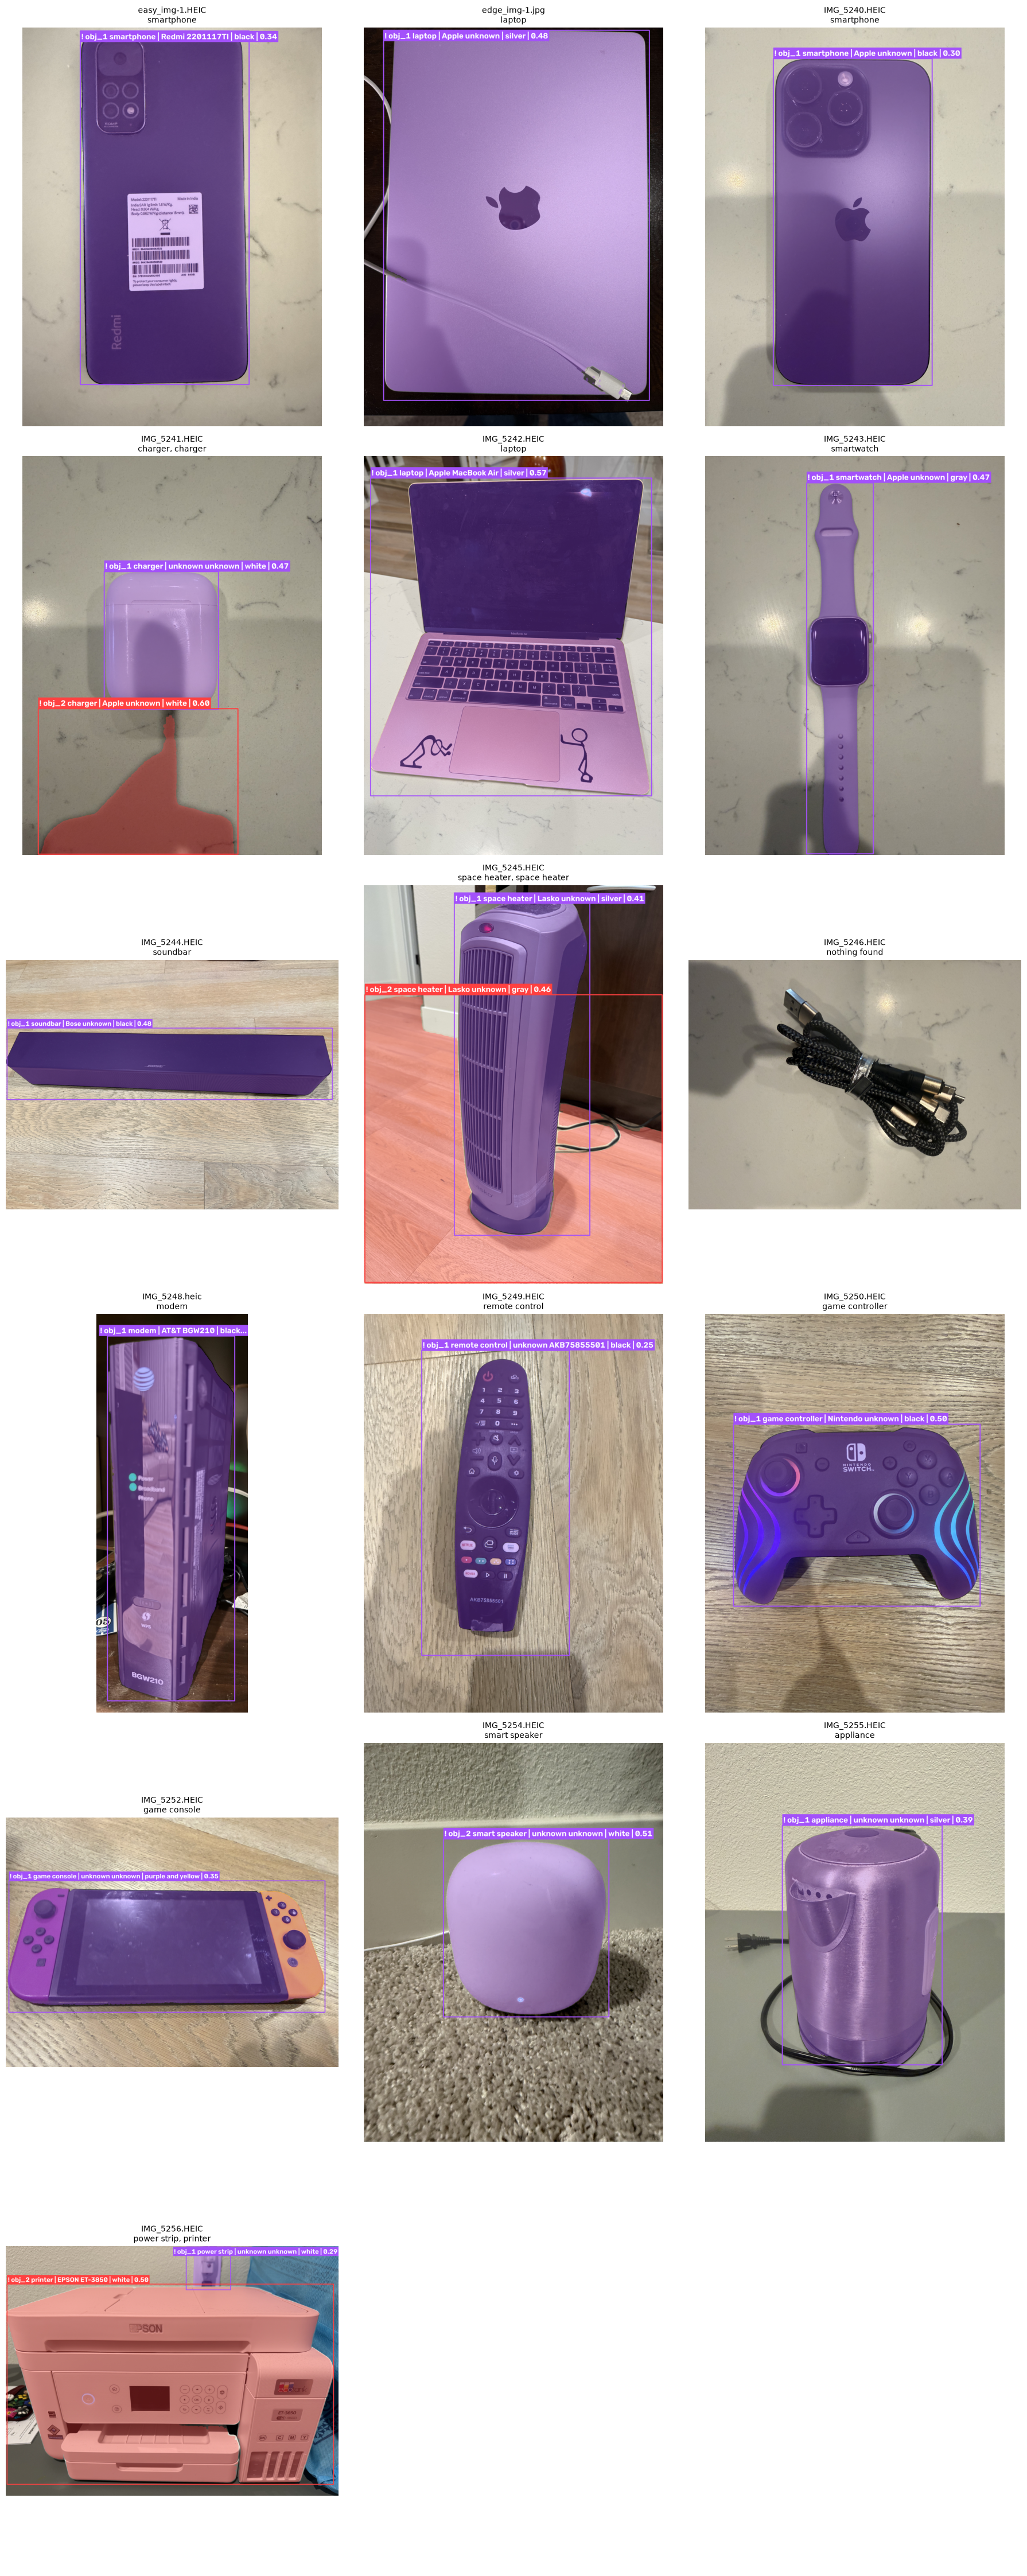

In [20]:
GRID_DRAWER(
    runs,
    columns=GRID_COLS,
    cell_size=CELL_SIZE,
    max_side=DISPLAY_MAX_SIDE,
    title_fn=TITLE_FORMATTER,
    image_attr="annotated",        # or "original"
)

## 7. JSON outputs

One block per image, exactly as the pipeline writes `result.json`:

* `items[].bbox_xyxy`: box in the **original** image's pixels,
* `items[].detector_phrase` / `detector_confidence`: what the detector matched,
* `items[].attributes`: the schema.org product (`brand`, `model`, `category`, `color`),
* `items[].warnings`: reasons to double-check an item (for example `CATEGORY_NOVEL`, `BRAND_UNKNOWN`, `CATEGORY_MISMATCH`),
* `meta`: the config hash and the component names used (hide it with `JSON_DROP_META = True`).

In [21]:
JSON_PRINTER(runs, json_fn=JSON_FORMATTER, drop_meta=JSON_DROP_META)

easy_img-1.HEIC   (45.4s)
{
  "image_width": 3024,
  "image_height": 4032,
  "items": [
    {
      "id": "obj_1",
      "bbox_xyxy": [
        583,
        35,
        2290,
        3610
      ],
      "detector_phrase": "electronic device",
      "detector_confidence": 0.3354375660419464,
      "attributes": {
        "@context": "https://schema.org",
        "@type": "Product",
        "brand": "Redmi",
        "model": "2201117TI",
        "category": "smartphone",
        "color": "black"
      },
      "warnings": [
        "LOW_DETECTOR_CONFIDENCE"
      ]
    }
  ],
  "annotated_image_format": "png",
  "meta": {
    "config_hash": "ee90bf0085d4",
    "components": {
      "image_preprocess": [
        "ensure_rgb_uint8",
        "resize_max_side"
      ],
      "detector": "ram_grounding_dino",
      "detection_filter": [
        "score_threshold",
        "min_size",
        "min_area_ratio",
        "full_frame_guard",
        "nms",
        "containment",
        "top_k"
   

## 8. Summary table

The same results in one table, for scanning many images quickly.

In [22]:
SUMMARY_PRINTER(runs)

image            items  dropped  categories                  warnings                                                                seconds
---------------  -----  -------  --------------------------  ----------------------------------------------------------------------  -------
easy_img-1.HEIC  1      0        smartphone                  LOW_DETECTOR_CONFIDENCE                                                 45.4   
edge_img-1.jpg   1      1        laptop                      CATEGORY_MISMATCH, MODEL_UNKNOWN                                        46.9   
IMG_5240.HEIC    1      0        smartphone                  LOW_DETECTOR_CONFIDENCE, MODEL_UNKNOWN                                  32.0   
IMG_5241.HEIC    2      0        charger, charger            BRAND_UNKNOWN, CATEGORY_MISMATCH, MODEL_UNKNOWN                         62.3   
IMG_5242.HEIC    1      0        laptop                      CATEGORY_MISMATCH                                                       20.2   
IMG_5243.HEIC

### 8b. Per-item details: what the detector proposed and what the VLM decided

One row per item: the phrase the detector used (from the RAM++ tags or the vocabulary), the category the VLM settled on, and the attributes it read. A mismatch between the two phrases is how the VLM corrects the detector.


In [23]:
def show_item_details(runs: list[ImageRun]) -> None:
    """Print one line per item: detector phrase -> VLM category, brand, model, color, warnings."""
    rows = []
    for run in runs:
        if not run.ok:
            continue
        for item in run.result.items:
            a = item.attributes
            rows.append({
                "image": run.name,
                "id": item.id,
                "detector": f"{item.detector_phrase} ({item.detector_confidence:.2f})",
                "category": a.category,
                "brand": a.brand,
                "model": a.model,
                "color": a.color,
                "warnings": ", ".join(item.warnings) or "-",
            })
    if not rows:
        print("no items found")
        return
    columns = list(rows[0])
    widths = {c: min(max(len(c), *(len(str(r[c])) for r in rows)), 46) for c in columns}
    print("  ".join(c.ljust(widths[c]) for c in columns))
    print("  ".join("-" * widths[c] for c in columns))
    for r in rows:
        print("  ".join(str(r[c])[: widths[c]].ljust(widths[c]) for c in columns))


show_item_details(runs)


image            id     detector                  category         brand     model        color              warnings                                      
---------------  -----  ------------------------  ---------------  --------  -----------  -----------------  ----------------------------------------------
easy_img-1.HEIC  obj_1  electronic device (0.34)  smartphone       Redmi     2201117TI    black              LOW_DETECTOR_CONFIDENCE                       
edge_img-1.jpg   obj_1  computer (0.48)           laptop           Apple     unknown      silver             MODEL_UNKNOWN, CATEGORY_MISMATCH              
IMG_5240.HEIC    obj_1  electronic device (0.30)  smartphone       Apple     unknown      black              MODEL_UNKNOWN, LOW_DETECTOR_CONFIDENCE        
IMG_5241.HEIC    obj_1  smart speaker (0.47)      charger          unknown   unknown      white              BRAND_UNKNOWN, MODEL_UNKNOWN, CATEGORY_MISMATC
IMG_5241.HEIC    obj_2  shadow (0.60)             charger       

## 9. Optional extras

### 9a. Save everything to disk

Set `SAVE_DIR` in the configuration cell (for example `Path("notebook_outputs")`) and re-run this cell. It writes `annotated.png` and `result.json` into one sub-folder per image.

In [24]:
def save_runs(runs: list[ImageRun], folder: Path, drop_meta: bool = False) -> None:
    """Write ``<folder>/<image name>/annotated.png`` and ``result.json`` for every successful run."""
    for run in runs:
        if not run.ok:
            continue
        target = Path(folder) / run.path.stem
        target.mkdir(parents=True, exist_ok=True)
        Image.fromarray(run.annotated).save(target / "annotated.png")
        (target / "result.json").write_text(JSON_FORMATTER(run, drop_meta), encoding="utf-8")
    print(f"saved to {Path(folder).resolve()}")


if SAVE_DIR is not None:
    save_runs(runs, SAVE_DIR, JSON_DROP_META)
else:
    print("SAVE_DIR is None, nothing saved. Set it in the configuration cell to enable saving.")

SAVE_DIR is None, nothing saved. Set it in the configuration cell to enable saving.


### 9b. Inspect the filter steps for one image

Needs `CAPTURE_TRACE = True` (then re-run sections 5 to 8). The trace records the detections after **each** detection filter, which shows *which filter removed which box*. This is the quickest way to debug duplicate or missing boxes.

In [25]:
def show_filter_steps(run: ImageRun) -> None:
    """Print how many detections survived each filter, and which phrases are left."""
    if run.trace is None:
        print("No trace for this image. Set CAPTURE_TRACE = True and re-run the pipeline cells.")
        return
    print(f"{run.name}: raw detections = {len(run.trace.raw_detections)}, "
          f"after phrase mapping = {len(run.trace.mapped_detections)}")
    for name, detections in run.trace.filter_steps:
        phrases = ", ".join(f"{d.phrase} {d.confidence:.2f}" for d in detections) or "-"
        print(f"  after {name:<18} {len(detections):>2}   {phrases}")


# Pick an image by (part of) its file name; change this to look at another one.
INSPECT = "5255"
for run in runs:
    if INSPECT in run.name:
        show_filter_steps(run)

IMG_5255.HEIC: raw detections = 8, after phrase mapping = 8
  after score_threshold     8   cable 0.46, power strip 0.29, home appliance 0.39, power strip 0.34, usb hub 0.33, boiler 0.25, home appliance 0.27, remote control 0.27
  after min_size            8   cable 0.46, power strip 0.29, home appliance 0.39, power strip 0.34, usb hub 0.33, boiler 0.25, home appliance 0.27, remote control 0.27
  after min_area_ratio      5   cable 0.46, home appliance 0.39, boiler 0.25, home appliance 0.27, remote control 0.27
  after full_frame_guard    5   cable 0.46, home appliance 0.39, boiler 0.25, home appliance 0.27, remote control 0.27
  after nms                 3   cable 0.46, home appliance 0.39, remote control 0.27
  after containment         3   cable 0.46, home appliance 0.39, remote control 0.27
  after top_k               3   cable 0.46, home appliance 0.39, remote control 0.27


## 10. Cheat sheet: swapping a feature

| I want to... | Change |
|---|---|
| Process one image completely before the next (more memory) | `TWO_PHASE = False` |
| Try only a few images | `MAX_IMAGES = 3` or `ONLY = ["5255"]` |
| Test quickly without the VLM | `USE_FAKE_VLM = True` |
| Use another Ollama model | `SETS = ["pipeline.vlm.client.params.model=<name from `ollama list`>"]` |
| Run the VLM inside Python | `SETS = ["pipeline.vlm.client.name=transformers"]` and add its `model_name` param |
| Use the fast preset | `PRESETS = ["fast"]` |
| Compare with the old pipeline (DINO + fixed vocabulary, no masks) | `PRESETS = ["baseline"]` |
| Go back to the closed category list | `SETS = ["pipeline.attribute_postprocess=[{name: normalize_unknown}, {name: ocr_verify_model}, {name: category_vocab}]"]` |
| Turn the SAM masks off | `SETS = ["pipeline.segmenter.name=none"]` |
| Run RAM++ on the CPU (if the GPU fails) | `SETS = ["pipeline.detector.params.ram_on_cpu=true"]` |
| Keep items the VLM says are not devices | `SETS = ["pipeline.vlm.on_not_electronic=warn"]` |
| Change detector thresholds | `SETS = ["pipeline.detection_filters=[...]"]` (lists are replaced whole) |
| Use my own VLM / detector class | `EXTRA_COMPONENTS = {"vlm_client": MyClient()}` |
| Change how images are loaded | write a function and set `IMAGE_LOADER = my_loader` |
| Change the picture grid | `GRID_COLS`, `CELL_SIZE`, or set `GRID_DRAWER = my_function` |
| Compare two configurations | run sections 5-6 twice, keeping the first list in another variable, e.g. `runs_a = runs`, then `GRID_DRAWER(runs_a + runs_b)` |
| See all available components and their parameters | in a terminal: `python -m electronics_classifier.cli list-components` |